# НИРМ3 — неделя 6: исследовательский анализ данных PTB-XL

Продолжение `nirm3_week5_ptbxl.ipynb` (использует кэш недель 3–5: метрики качества сигналов, метки и
разбиение, предсказания ResNet1d на фолдах 9 и 10). Обучения на этой неделе нет — только анализ.

Задачи недели 6 (календарный план):
1. Баланс классов: распространённость суперклассов в целом, по полу и по возрасту.
2. Статистика пациентов по возрасту и полу; полнота антропометрии.
3. Шумы и артефакты: связь флагов качества с типом аппарата и полом (открытый вопрос недели 3)
   и влияние помех на качество распознавания ResNet1d.
4. Итоговая сводка выборок train/val/test.

Задачи из плана недели 5, не требующие обучения:
5. Пороги скрининга, подобранные отдельно по полу.
6. Разбор пропусков MI у женщин: подтипы инфаркта, стадия, возраст.

`seed=42`, PTB-XL v1.0.3, `records100`.

In [1]:
import ast
import glob
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

SEED = 42
DATA_PATH = os.path.dirname(glob.glob('**/ptbxl_database.csv', recursive=True)[0]) + os.sep
CACHE = 'cache' + os.sep
FIG_DIR = CACHE + 'fig' + os.sep
assert os.path.exists(CACHE + 'resnet1d_scores.npz'), 'сначала выполните ноутбуки недель 3–5'
plt.rcParams.update({'font.size': 9, 'axes.grid': True, 'grid.alpha': 0.3})
SEX_COLORS = {'male': '#4C72B0', 'female': '#C44E52'}

df = pd.read_csv(DATA_PATH + 'ptbxl_database.csv', index_col='ecg_id')
df['scp_codes'] = df.scp_codes.apply(ast.literal_eval)
scp = pd.read_csv(DATA_PATH + 'scp_statements.csv', index_col=0)
scp = scp[scp.diagnostic == 1]
SUPERCLASSES = ['NORM', 'MI', 'STTC', 'CD', 'HYP']
df['sex_label'] = df.sex.map({0: 'male', 1: 'female'})
df['age_clean'] = df.age.where(df.age != 300, 90)  # 300 в PTB-XL означает «старше 89 лет»

q = pd.read_csv(CACHE + 'quality_full.csv', index_col='ecg_id')
lab = np.load(CACHE + 'labels_splits.npz', allow_pickle=True)
Y, split, has_label = lab['Y'].astype(int), lab['split'], lab['has_label']
assert (lab['ecg_ids'] == df.index.to_numpy()).all() and (q.index == df.index).all()
tr, va, te = [(split == s) & has_label for s in ('train', 'val', 'test')]
scores = np.load(CACHE + 'resnet1d_scores.npz')
s_val, s_test = scores['s_val'], scores['s_test']
sex = df.sex_label.to_numpy()
print(f'записей {len(df)}, с диагнозом {has_label.sum()}; train {tr.sum()}, val {va.sum()}, test {te.sum()}')

записей 21799, с диагнозом 21388; train 17084, val 2146, test 2158


## Задача 1. Баланс классов

Задача многометочная, поэтому дисбаланс считается для каждого суперкласса отдельно: отношение
отрицательных примеров к положительным. Дополнительно — распространённость по полу и по возрастным
группам: если распределение классов у мужчин и женщин разное, общая модель видит женские примеры
каждого класса реже.

In [2]:
AGE_BINS = [0, 40, 60, 80, 200]
AGE_LABELS = ['<40', '40-59', '60-79', '80+']
df['age_group'] = pd.cut(df.age_clean, AGE_BINS, right=False, labels=AGE_LABELS)

Yl = pd.DataFrame(Y[has_label], columns=SUPERCLASSES, index=df.index[has_label])
meta = df.loc[has_label, ['sex_label', 'age_group', 'age_clean']]

balance = pd.DataFrame({
    'positive': Yl.sum(),
    'prevalence_%': (Yl.mean() * 100).round(1),
    'neg/pos': ((len(Yl) - Yl.sum()) / Yl.sum()).round(2),
    'male_%': (Yl[meta.sex_label == 'male'].mean() * 100).round(1),
    'female_%': (Yl[meta.sex_label == 'female'].mean() * 100).round(1),
})
balance['female_share_of_pos_%'] = (Yl[meta.sex_label == 'female'].sum() / Yl.sum() * 100).round(1)
print(balance.to_string())

by_age = (Yl.groupby(meta.age_group, observed=True).mean() * 100).round(1)
by_age['records'] = meta.age_group.value_counts().reindex(AGE_LABELS).to_numpy()
print('\nраспространённость по возрасту, %:')
print(by_age.to_string())

      positive  prevalence_%  neg/pos  male_%  female_%  female_share_of_pos_%
NORM      9514          44.5     1.25    39.5      49.9                   53.9
MI        5469          25.6     2.91    30.7      20.1                   37.7
STTC      5235          24.5     3.09    23.1      26.0                   51.0
CD        4898          22.9     3.37    27.0      18.5                   38.8
HYP       2649          12.4     7.07    13.7      11.0                   42.6

распространённость по возрасту, %:
           NORM    MI  STTC    CD   HYP  records
age_group                                       
<40        81.4   4.6   7.1  11.2   4.6     2828
40-59      55.4  20.8  18.4  16.2   8.9     6801
60-79      32.7  31.9  29.8  27.2  15.5     9130
80+        17.3  38.7  40.4  37.8  18.9     2629


## Задача 2. Пациенты: возраст, пол, антропометрия

In [3]:
pat = df.groupby('patient_id').agg(sex_label=('sex_label', 'first'), age=('age_clean', 'min'),
                                   n_records=('sex_label', 'size'))
demo = pd.DataFrame({
    'records': df.sex_label.value_counts(),
    'patients': pat.sex_label.value_counts(),
    'age_median': df.groupby('sex_label').age_clean.median(),
    'age_IQR': df.groupby('sex_label').age_clean.apply(lambda a: f'{a.quantile(.25):.0f}-{a.quantile(.75):.0f}'),
    'age_80plus_%': df.groupby('sex_label').age_clean.apply(lambda a: round((a >= 80).mean() * 100, 1)),
}).loc[['male', 'female']]
print(demo.to_string())
print(f'\nпациентов: {len(pat)}; с несколькими записями: {(pat.n_records > 1).sum()} '
      f'({(pat.n_records > 1).mean() * 100:.1f}%), максимум записей на пациента: {pat.n_records.max()}')
print(f'возраст закодирован как 300 (>89 лет): {(df.age == 300).sum()} записей')
print(f'рост указан у {df.height.notna().mean() * 100:.1f}% записей, вес — у {df.weight.notna().mean() * 100:.1f}%, '
      f'оба — у {(df.height.notna() & df.weight.notna()).mean() * 100:.1f}%')

           records  patients  age_median age_IQR  age_80plus_%
sex_label                                                     
male         11354      9640        61.0   50-70           8.2
female       10445      9229        64.0   50-75          17.0

пациентов: 18869; с несколькими записями: 2111 (11.2%), максимум записей на пациента: 10
возраст закодирован как 300 (>89 лет): 293 записей
рост указан у 32.0% записей, вес — у 43.2%, оба — у 31.0%


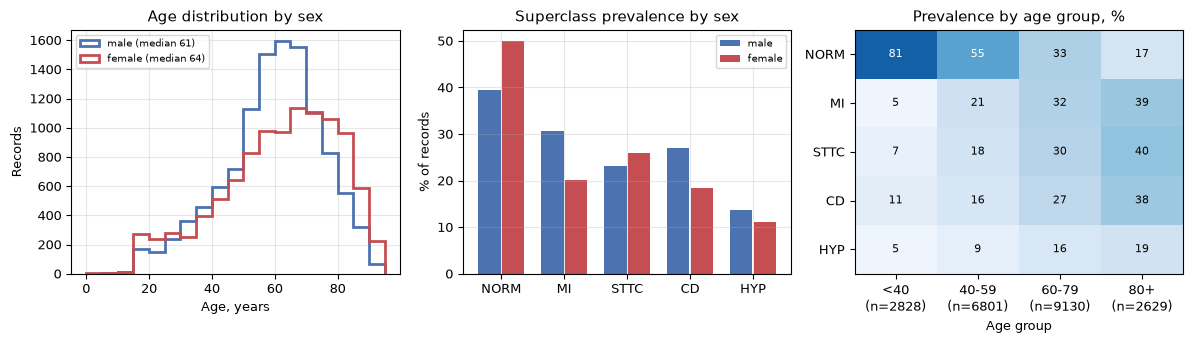

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
bins = np.arange(0, 96, 5)
for s in ('male', 'female'):
    ax[0].hist(df.age_clean[df.sex_label == s], bins=bins, histtype='step', lw=2, color=SEX_COLORS[s],
               label=f'{s} (median {demo.loc[s, "age_median"]:.0f})')
ax[0].set(xlabel='Age, years', ylabel='Records', title='Age distribution by sex')
ax[0].legend(fontsize=7)

x = np.arange(len(SUPERCLASSES))
for k, s in enumerate(('male', 'female')):
    ax[1].bar(x + (k - 0.5) * 0.38, balance[f'{s}_%'], 0.36, color=SEX_COLORS[s], label=s)
ax[1].set_xticks(x, SUPERCLASSES)
ax[1].set(ylabel='% of records', title='Superclass prevalence by sex')
ax[1].legend(fontsize=7)

heat = by_age[SUPERCLASSES].T.to_numpy()
ax[2].imshow(heat, cmap='Blues', vmin=0, vmax=100, aspect='auto')
for a in range(heat.shape[0]):
    for b in range(heat.shape[1]):
        ax[2].text(b, a, f'{heat[a, b]:.0f}', ha='center', va='center', fontsize=8,
                   color='white' if heat[a, b] > 55 else 'black')
ax[2].set_xticks(range(len(AGE_LABELS)), [f'{g}\n(n={n})' for g, n in zip(AGE_LABELS, by_age.records)])
ax[2].set_yticks(range(len(SUPERCLASSES)), SUPERCLASSES)
ax[2].grid(False)
ax[2].set(xlabel='Age group', title='Prevalence by age group, %')
plt.tight_layout()
plt.savefig(FIG_DIR + 'w6_demographics.png', dpi=150)
plt.show()

## Задача 3. Шумы и артефакты

На неделе 3 автоматический флаг качества чаще срабатывал на женских записях (29.3 % против 22.7 %) при
одинаковой врачебной разметке помех, а гипотеза о меньшей амплитуде не подтвердилась. Проверяем другое
объяснение — тип регистрирующего аппарата: PTB-XL собирался на нескольких моделях Schiller, и если
женщин чаще снимали на «шумных» аппаратах, разница в флагах объясняется аппаратом, а не полом.

In [5]:
df['device_family'] = df.device.str.extract(r'^(CS|AT)', expand=False).fillna('other')
qd = q.join(df[['device_family', 'sex_label']])
ann_any = df[['baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems']].notna().any(axis=1)
qd['annotated'] = ann_any

dev = qd.groupby('device_family').agg(records=('flag_any', 'size'),
                                      female_pct=('sex_label', lambda s: (s == 'female').mean() * 100),
                                      flag_drift_pct=('flag_drift', lambda f: f.mean() * 100),
                                      flag_any_pct=('flag_any', lambda f: f.mean() * 100),
                                      annotated_pct=('annotated', lambda f: f.mean() * 100)).round(1)
print(dev.to_string())

dev_sex = (qd.groupby(['device_family', 'sex_label']).flag_drift.mean() * 100).unstack()[['male', 'female']]
dev_sex['female - male, p.p.'] = dev_sex.female - dev_sex.male
print('\nфлаг дрейфа по аппарату и полу, %:')
print(dev_sex.round(1).to_string())

weights = qd.device_family.value_counts(normalize=True)
std_rate = {s: (dev_sex[s] * weights.reindex(dev_sex.index)).sum() for s in ('male', 'female')}
print(f'\nфлаг дрейфа, стандартизованный по аппарату: male {std_rate["male"]:.1f}%, '
      f'female {std_rate["female"]:.1f}% (без стандартизации '
      f'{qd.flag_drift[qd.sex_label == "male"].mean() * 100:.1f}% и '
      f'{qd.flag_drift[qd.sex_label == "female"].mean() * 100:.1f}%)')
print(f'\nдругие пометки: extra_beats {df.extra_beats.notna().sum()}, pacemaker {df.pacemaker.notna().sum()}')

               records  female_pct  flag_drift_pct  flag_any_pct  annotated_pct
device_family                                                                  
AT                8733        53.7            19.0          32.0           12.3
CS               13066        44.1             7.0          21.8           30.1

флаг дрейфа по аппарату и полу, %:
sex_label      male  female  female - male, p.p.
device_family                                   
AT             18.1    19.8                  1.7
CS              5.5     9.0                  3.6

флаг дрейфа, стандартизованный по аппарату: male 10.5%, female 13.4% (без стандартизации 10.0% и 13.9%)

другие пометки: extra_beats 1949, pacemaker 291


### Влияет ли шум на качество распознавания?

Сравниваем AUC ResNet1d (неделя 5) на тестовом фолде 10 для записей с врачебной пометкой помех и без
неё; интервал для разности — бутстреп по записям внутри каждой группы.

In [6]:
N_BOOT = 1000


def macro_auc(y, s):
    return np.mean([roc_auc_score(y[:, k], s[:, k]) for k in range(y.shape[1])])


y_te = Y[te]
noisy_te = ann_any.to_numpy()[te]
auto_te = q.flag_any.to_numpy()[te]
sex_te = sex[te]

rows = []
for name, m in (('physician annotation', noisy_te), ('auto QC flag', auto_te)):
    rng = np.random.default_rng(SEED)
    a_idx, b_idx = np.where(m)[0], np.where(~m)[0]
    diffs = []
    for _ in range(N_BOOT):
        ia, ib = rng.choice(a_idx, len(a_idx)), rng.choice(b_idx, len(b_idx))
        diffs.append(macro_auc(y_te[ia], s_test[ia]) - macro_auc(y_te[ib], s_test[ib]))
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    rows.append({'marker': name, 'n_noisy': int(m.sum()), 'n_clean': int((~m).sum()),
                 'macro-AUC noisy': macro_auc(y_te[m], s_test[m]), 'macro-AUC clean': macro_auc(y_te[~m], s_test[~m]),
                 'noisy - clean': macro_auc(y_te[m], s_test[m]) - macro_auc(y_te[~m], s_test[~m]),
                 'CI low': lo, 'CI high': hi})
noise_effect = pd.DataFrame(rows).set_index('marker')
print(noise_effect.round(3).to_string())

per_class_noise = pd.DataFrame({
    'annotated': [roc_auc_score(y_te[noisy_te, k], s_test[noisy_te, k]) for k in range(5)],
    'clean': [roc_auc_score(y_te[~noisy_te, k], s_test[~noisy_te, k]) for k in range(5)]}, index=SUPERCLASSES)
print('\nAUC по классам, записи с врачебной пометкой помех и без:')
print(per_class_noise.round(3).to_string())

gap_clean = (macro_auc(y_te[(sex_te == 'female') & ~noisy_te], s_test[(sex_te == 'female') & ~noisy_te])
             - macro_auc(y_te[(sex_te == 'male') & ~noisy_te], s_test[(sex_te == 'male') & ~noisy_te]))
gap_all = (macro_auc(y_te[sex_te == 'female'], s_test[sex_te == 'female'])
           - macro_auc(y_te[sex_te == 'male'], s_test[sex_te == 'male']))
print(f'\nразрыв macro-AUC женщины - мужчины: все записи {gap_all:+.3f}, только без помех {gap_clean:+.3f}')

                      n_noisy  n_clean  macro-AUC noisy  macro-AUC clean  noisy - clean  CI low  CI high
marker                                                                                                  
physician annotation      513     1645            0.923            0.932         -0.009  -0.030    0.008
auto QC flag              581     1577            0.927            0.930         -0.003  -0.017    0.012

AUC по классам, записи с врачебной пометкой помех и без:
      annotated  clean
NORM      0.943  0.951
MI        0.917  0.938
STTC      0.932  0.940
CD        0.932  0.921
HYP       0.889  0.909

разрыв macro-AUC женщины - мужчины: все записи -0.020, только без помех -0.016


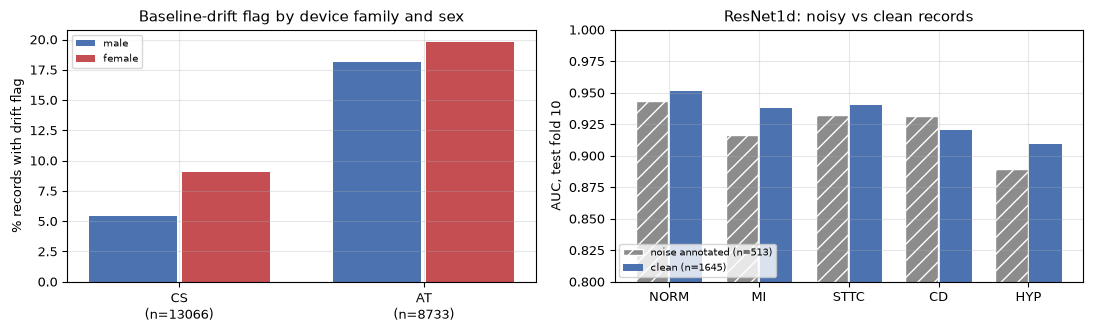

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
fam = [f for f in ('CS', 'AT', 'other') if f in dev_sex.index]
xf = np.arange(len(fam))
for k, s in enumerate(('male', 'female')):
    ax[0].bar(xf + (k - 0.5) * 0.38, dev_sex.loc[fam, s], 0.36, color=SEX_COLORS[s], label=s)
ax[0].set_xticks(xf, [f'{f}\n(n={dev.loc[f, "records"]})' for f in fam])
ax[0].set(ylabel='% records with drift flag', title='Baseline-drift flag by device family and sex')
ax[0].legend(fontsize=7)
ax[1].bar(x - 0.19, per_class_noise.annotated, 0.36, color='#8C8C8C', hatch='//', edgecolor='white',
          label=f'noise annotated (n={noisy_te.sum()})')
ax[1].bar(x + 0.19, per_class_noise.clean, 0.36, color='#4C72B0', label=f'clean (n={(~noisy_te).sum()})')
ax[1].set_xticks(x, SUPERCLASSES)
ax[1].set(ylim=(0.8, 1.0), ylabel='AUC, test fold 10', title='ResNet1d: noisy vs clean records')
ax[1].legend(fontsize=7, loc='lower left')
plt.tight_layout()
plt.savefig(FIG_DIR + 'w6_noise.png', dpi=150)
plt.show()

## Задача 4. Итоговая сводка выборок

Разбиение недели 4 (`strat_fold` 1–8 / 9 / 10) не меняется; здесь — сводная таблица для отчёта.

In [8]:
rows = []
for name, m in (('train', tr), ('val', va), ('test', te)):
    rows.append({'split': name, 'records': int(m.sum()), 'patients': df.patient_id[m].nunique(),
                 'female_%': round((sex[m] == 'female').mean() * 100, 1),
                 'age_median': df.age_clean[m].median(),
                 'noise_annotated_%': round(ann_any[m].mean() * 100, 1),
                 'validated_%': round(df.validated_by_human[m].mean() * 100, 1),
                 **{f'{c}_%': round(Y[m, k].mean() * 100, 1) for k, c in enumerate(SUPERCLASSES)}})
split_summary = pd.DataFrame(rows).set_index('split')
print(split_summary.T.to_string())

split                train     val    test
records            17084.0  2146.0  2158.0
patients           14823.0  1917.0  1877.0
female_%              48.0    48.1    48.6
age_median            61.0    62.0    63.0
noise_annotated_%     22.7    24.6    23.8
validated_%           67.8   100.0   100.0
NORM_%                44.5    44.5    44.6
MI_%                  25.6    25.2    25.5
STTC_%                24.5    24.6    24.1
CD_%                  22.9    23.1    23.0
HYP_%                 12.4    12.5    12.1


## Задача 5. Пороги скрининга по полу

На неделе 5 общий порог (чувствительность ≥ 0.90 на фолде 9) дал у женщин заметно более низкую
чувствительность по MI, CD и HYP. Здесь пороги подбираются на фолде 9 отдельно для мужчин и женщин тем же
правилом и применяются на тесте к записям соответствующего пола. Интервалы для чувствительности —
по Уилсону.

In [9]:
TARGET_SENS = 0.90


def screening_thresholds(y_val, s_val, target=TARGET_SENS):
    th = []
    for k in range(y_val.shape[1]):
        pos_scores = np.sort(s_val[y_val[:, k] == 1, k])
        th.append(pos_scores[int(np.floor((1 - target) * len(pos_scores)))])
    return np.array(th)


def wilson(k, n, z=1.96):
    p_hat = k / n
    centre = (p_hat + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    half = z * np.sqrt(p_hat * (1 - p_hat) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    return centre - half, centre + half


y_va, sex_va = Y[va], sex[va]
th_common = screening_thresholds(y_va, s_val)
th_sex = {s: screening_thresholds(y_va[sex_va == s], s_val[sex_va == s]) for s in ('male', 'female')}

rows = []
for policy in ('common', 'sex-specific'):
    for s in ('male', 'female'):
        m = sex_te == s
        th = th_common if policy == 'common' else th_sex[s]
        for k, c in enumerate(SUPERCLASSES):
            yk, pred = y_te[m, k], s_test[m, k] >= th[k]
            tp, n_pos = int(pred[yk == 1].sum()), int(yk.sum())
            lo, hi = wilson(tp, n_pos)
            rows.append({'policy': policy, 'sex': s, 'class': c, 'n_pos': n_pos, 'sens': tp / n_pos,
                         'sens_lo': lo, 'sens_hi': hi, 'spec': 1 - pred[yk == 0].mean(),
                         'flagged_%': pred.mean() * 100})
thr = pd.DataFrame(rows)
print('чувствительность на тесте:')
print(thr.pivot_table(index='class', columns=['policy', 'sex'], values='sens').loc[SUPERCLASSES].round(3).to_string())
print('\nспецифичность на тесте:')
print(thr.pivot_table(index='class', columns=['policy', 'sex'], values='spec').loc[SUPERCLASSES].round(3).to_string())

gap = thr.pivot_table(index=['policy', 'class'], columns='sex', values='sens')
gap = (gap.female - gap.male).unstack('policy').loc[SUPERCLASSES]
print('\nразрыв чувствительности женщины - мужчины:')
print(gap.round(3).to_string())
print('\nпороги на фолде 9:')
print(pd.DataFrame({'common': th_common, **th_sex}, index=SUPERCLASSES).round(3).to_string())

чувствительность на тесте:
policy common        sex-specific       
sex    female   male       female   male
class                                   
NORM    0.922  0.930        0.899  0.946
MI      0.866  0.949        0.901  0.926
STTC    0.887  0.865        0.884  0.865
CD      0.848  0.925        0.857  0.917
HYP     0.858  0.904        0.882  0.874

специфичность на тесте:
policy common        sex-specific       
sex    female   male       female   male
class                                   
NORM    0.819  0.850        0.834  0.840
MI      0.787  0.786        0.760  0.818
STTC    0.811  0.868        0.813  0.866
CD      0.825  0.756        0.808  0.771
HYP     0.750  0.732        0.707  0.760

разрыв чувствительности женщины - мужчины:
policy  common  sex-specific
class                       
NORM    -0.009        -0.046
MI      -0.084        -0.025
STTC     0.022         0.019
CD      -0.077        -0.061
HYP     -0.045         0.008

пороги на фолде 9:
      common   male  fema

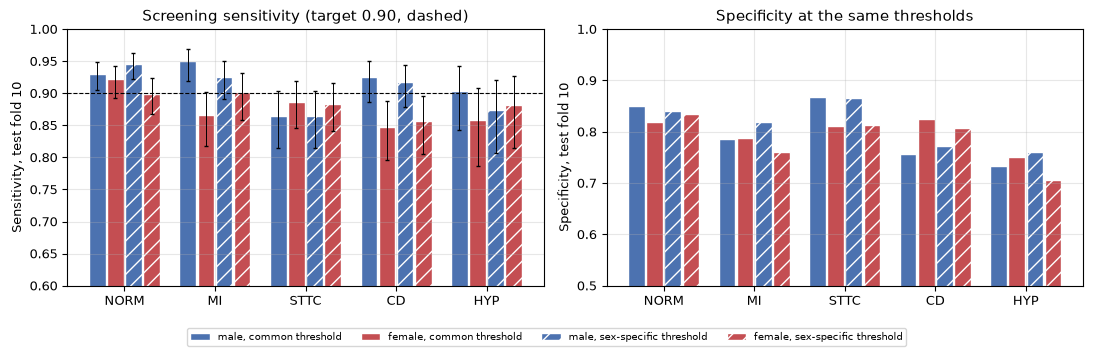

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
w = 0.2
for j, (policy, hatch) in enumerate((('common', ''), ('sex-specific', '//'))):
    for k, s in enumerate(('male', 'female')):
        sub = thr[(thr.policy == policy) & (thr.sex == s)].set_index('class').loc[SUPERCLASSES]
        pos = x + (2 * j + k - 1.5) * w
        for a, metric in zip(ax, ('sens', 'spec')):
            a.bar(pos, sub[metric], w * 0.92, color=SEX_COLORS[s], hatch=hatch, edgecolor='white',
                  label=f'{s}, {policy} threshold')
        ax[0].errorbar(pos, sub.sens, yerr=[sub.sens - sub.sens_lo, sub.sens_hi - sub.sens], fmt='none',
                       ecolor='black', elinewidth=0.7, capsize=1.5)
ax[0].axhline(TARGET_SENS, color='black', ls='--', lw=0.8)
ax[0].set(ylim=(0.6, 1.0), ylabel='Sensitivity, test fold 10', title='Screening sensitivity (target 0.90, dashed)')
ax[1].set(ylim=(0.5, 1.0), ylabel='Specificity, test fold 10', title='Specificity at the same thresholds')
for a in ax:
    a.set_xticks(x, SUPERCLASSES)
handles, labels = ax[1].get_legend_handles_labels()
fig.legend(handles, labels, ncol=4, fontsize=7, loc='lower center')
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.savefig(FIG_DIR + 'w6_thresholds.png', dpi=150)
plt.show()

## Задача 6. Пропуски инфаркта у женщин

Подтипы MI в PTB-XL (`diagnostic_subclass`): IMI — нижний, AMI — передний, LMI — боковой, PMI — задний.
Если у женщин другая структура подтипов или стадий, это может объяснить более низкую чувствительность
при общем пороге. Анализ — на MI-положительных записях теста при общем пороге недели 5.

In [11]:
mi_sub = scp[scp.diagnostic_class == 'MI'].diagnostic_subclass
k_mi = SUPERCLASSES.index('MI')
te_ids = df.index[te]
mi_pos = y_te[:, k_mi] == 1
detected = s_test[:, k_mi] >= th_common[k_mi]

mi = pd.DataFrame({'sex': sex_te[mi_pos], 'detected': detected[mi_pos], 'score': s_test[mi_pos, k_mi]},
                  index=te_ids[mi_pos])
codes = df.loc[mi.index, 'scp_codes']
mi['subtypes'] = codes.apply(lambda c: sorted({mi_sub[k] for k in c if k in mi_sub.index}))
mi['n_subtypes'] = mi.subtypes.str.len()
mi['main'] = mi.subtypes.apply(lambda v: v[0] if len(v) == 1 else 'mixed')
mi['stadium'] = df.loc[mi.index, 'infarction_stadium1'].fillna('unknown')
mi['other_classes'] = y_te[mi_pos].sum(axis=1) - 1
mi['age_group'] = df.loc[mi.index, 'age_group'].astype(str)

comp = pd.crosstab(mi.main, mi.sex, normalize='columns').mul(100).round(1)[['male', 'female']]
comp['n'] = mi.main.value_counts()
print('структура подтипов MI в тесте, % внутри пола:')
print(comp.to_string())

sens_sub = mi.groupby(['main', 'sex']).detected.agg(['mean', 'size']).unstack('sex')
print('\nчувствительность по подтипу и полу (общий порог):')
print(sens_sub.round(3).to_string())

for col in ('stadium', 'age_group'):
    t = mi.groupby([col, 'sex']).detected.agg(['mean', 'size']).unstack('sex')
    print(f'\nчувствительность по {col}:')
    print(t.round(3).to_string())

# Насколько разрыв объясняется структурой подтипов: чувствительность женщин, перевзвешенная на структуру
# подтипов мужчин (прямая стандартизация)
s_f = mi[mi.sex == 'female'].groupby('main').detected.mean()
w_m = mi[mi.sex == 'male'].main.value_counts(normalize=True)
common_sub = s_f.index.intersection(w_m.index)
std_f = (s_f[common_sub] * w_m[common_sub]).sum() / w_m[common_sub].sum()
print(f'\nчувствительность MI: male {mi[mi.sex == "male"].detected.mean():.3f}, '
      f'female {mi[mi.sex == "female"].detected.mean():.3f}, '
      f'female при структуре подтипов мужчин {std_f:.3f}')

структура подтипов MI в тесте, % внутри пола:
sex    male  female    n
main                    
AMI    34.0    40.3  203
IMI    47.1    35.2  229
LMI     1.3     3.2   12
PMI     0.0     0.4    1
mixed  17.5    20.9  105

чувствительность по подтипу и полу (общий порог):
        mean          size       
sex   female   male female   male
main                             
AMI    0.882  0.960  102.0  101.0
IMI    0.820  0.943   89.0  140.0
LMI    0.500  0.250    8.0    4.0
PMI    0.000    NaN    1.0    NaN
mixed  0.981  1.000   53.0   52.0

чувствительность по stadium:
                 mean          size     
sex            female   male female male
stadium                                 
Stadium I       0.833  1.000      6    8
Stadium II      1.000  1.000      3    4
Stadium II-III  0.909  0.986     33   70
Stadium III     0.963  1.000     54   44
unknown         0.822  0.918    157  171

чувствительность по age_group:
            mean          size     
sex       female   male female

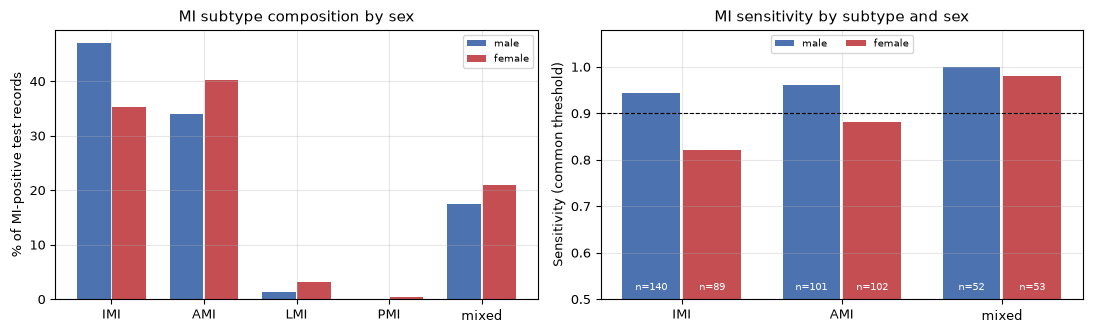

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
order = [s for s in ('IMI', 'AMI', 'LMI', 'PMI', 'mixed') if s in comp.index]
order_sens = [s for s in order if comp.loc[s, 'n'] >= 50]  # LMI и PMI: в тесте вместе 13 записей
xs, xs2 = np.arange(len(order)), np.arange(len(order_sens))
for k, s in enumerate(('male', 'female')):
    ax[0].bar(xs + (k - 0.5) * 0.38, comp.loc[order, s], 0.36, color=SEX_COLORS[s], label=s)
    ax[1].bar(xs2 + (k - 0.5) * 0.38, sens_sub.loc[order_sens, ('mean', s)], 0.36, color=SEX_COLORS[s], label=s)
    for xi, sub in zip(xs2, order_sens):
        ax[1].annotate(f'n={sens_sub.loc[sub, ("size", s)]:.0f}', (xi + (k - 0.5) * 0.38, 0.52), ha='center',
                       fontsize=7, color='white')
ax[0].set_xticks(xs, order)
ax[0].set(ylabel='% of MI-positive test records', title='MI subtype composition by sex')
ax[0].legend(fontsize=7)
ax[1].set_xticks(xs2, order_sens)
ax[1].legend(fontsize=7, loc='upper center', ncol=2)
ax[1].axhline(TARGET_SENS, color='black', ls='--', lw=0.8)
ax[1].set(ylim=(0.5, 1.08), ylabel='Sensitivity (common threshold)', title='MI sensitivity by subtype and sex')
plt.tight_layout()
plt.savefig(FIG_DIR + 'w6_mi_subtypes.png', dpi=150)
plt.show()

In [13]:
json.dump({'balance': balance.reset_index().to_dict('records'),
           'thresholds_common': th_common.tolist(),
           'thresholds_sex': {s: v.tolist() for s, v in th_sex.items()}},
          open(CACHE + 'w6_eda_summary.json', 'w'), default=float)
print('сохранено: w6_eda_summary.json и 4 рисунка w6_*.png')

сохранено: w6_eda_summary.json и 4 рисунка w6_*.png


## Выводы недели 6

**Баланс классов.** Дисбаланс в многометочной постановке — от 1.25 (NORM) до 7.07 (HYP) отрицательных на
один положительный пример. Распределение диагнозов по полу разное: у женщин чаще NORM (49.9 % против
39.5 %), реже MI (20.1 % против 30.7 %) и CD (18.5 % против 27.0 %); среди MI-положительных записей женщин
37.7 %, среди CD — 38.8 %. На один женский пример инфаркта в данных приходится 1.65 мужского. Патологии
резко растут с возрастом: NORM — 81 % записей до 40 лет и 17 % после 80.

**Пациенты.** 18 869 пациентов, у 11.2 % несколько записей (разбиение недели 4 по пациентам, утечек нет).
Женщины старше: медиана 64 года против 61, доля 80+ — 17.0 % против 8.2 %. Рост и вес указаны лишь у 31 %
записей, поэтому антропометрия (в т. ч. ИМТ из ИПРМ) как признак модели не используется.

**Шумы и аппараты.** На аппаратах AT флаг дрейфа срабатывает в 19.0 % записей против 7.0 % на CS, и женщин
среди AT-записей больше (53.7 % против 44.1 %). Но внутри каждого типа аппарата флаг у женщин всё равно чаще
(+1.7 и +3.6 п. п.); после стандартизации по аппарату разрыв сокращается лишь с 3.9 до 2.9 п. п. Аппарат
объясняет малую часть вопроса недели 3. Попутно: врачебная пометка помех на CS встречается в 2.4 раза чаще,
чем на AT (30.1 % против 12.3 %) — обратно автоматическому флагу, то есть практика разметки зависит от
аппарата (или центра), и врачебные пометки нельзя считать единым эталоном качества.

**Шум почти не влияет на ResNet1d.** На записях с врачебной пометкой помех macro-AUC 0.923 против 0.932 на
чистых (−0.009 [−0.030; 0.008], незначимо); заметнее всего по MI (0.917 против 0.938). Разрыв по полу
на одних только чистых записях −0.016 (на всех −0.020): помехи его не объясняют. Фильтрация 0.5–40 Гц
недели 3 достаточна, отбраковка записей не нужна.

**Пороги по полу помогают частично.** Пороги, подобранные на фолде 9 отдельно для каждого пола, сокращают
разрыв чувствительности по MI с −0.084 до −0.025 (у женщин 0.866 → 0.901) и по HYP с −0.045 до +0.008, но
почти не меняют CD (−0.077 → −0.061). Цена — специфичность у женщин: MI 0.787 → 0.760, HYP 0.750 → 0.707.
Интервалы широкие: в фолде 9 на пол приходится 120–270 положительных примеров. Вывод: часть разрыва —
калибровка (исправляется порогом), часть — различающая способность (AUC у женщин ниже), и её порогом
не исправить.

**Пропуски MI у женщин не объясняются структурой подтипов.** У женщин меньше нижних инфарктов (35.2 %
против 47.1 %) и больше передних (40.3 % против 34.0 %), но чувствительность ниже внутри каждого подтипа:
IMI 0.820 против 0.943, AMI 0.882 против 0.960. Если перевзвесить женские записи на мужскую структуру
подтипов, чувствительность не меняется (0.865 против 0.866). Разрыв есть во всех возрастных группах
(40–59: 0.765 против 0.899; 60–79: 0.855 против 0.961; 80+: 0.915 против 0.982). Стадия инфаркта у
большинства записей не указана, поэтому её роль оценить нельзя.

## План на неделю 7

1. Перенос обучения на GPU (Google Colab), повторное обучение ResNet1d в той же среде для честного сравнения.
2. Базовая 1D-CNN и подбор гиперпараметров (длина окна, ширина сети, learning rate) по фолду 9.
3. 3 запуска с разными seed для лучшей конфигурации — разброс macro-AUC и разрыва по полу.